# MLP Regression

## Setup

### Load

In [2]:
import os
import json
import pickle

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from scipy.stats import pearsonr

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error

from skorch import NeuralNetRegressor
from skorch.dataset import Dataset
from skorch.helper import predefined_split
from skorch.callbacks import EarlyStopping

### Path

In [3]:
SAVE_DIR = "regression"
os.makedirs(SAVE_DIR, exist_ok=True)
results_path = os.path.join(SAVE_DIR, "mlp_results.csv")

DATA_DIR = "data/data_integrated_irl.csv"

### Data

In [4]:
df_raw = pd.read_csv(DATA_DIR)
feature_cols = [
    'average_score_full',
    'bonus_score_episode_ratio',
    'road_crossing_success_ratio_total',
    'sideway_movements_in_crosswalk_not_visible_safe_zone_cnt_high_to_low_penalty',
    'run_over_episode_ratio',

    "safest_road_crossing_irl",
    "waiting_for_car_to_pass_irl",
    "high_risk_but_empty_last_road_irl",
    "approaching_crosswalk_in_current_road_irl",
    "approaching_next_crosswalks_irl",
    "move_up_toward_car_irl",
]
target_col = "DOSPERT"
df = df_raw[feature_cols + [target_col]].dropna()

### Util

In [5]:
class MLP_2_2_ReLU(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 2),
            nn.ReLU(),
            nn.Linear(2, 2),
            nn.ReLU(),
            nn.Linear(2, 1)
        )
    def forward(self, x):
        return self.net(x)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed) # Python random
    np.random.seed(seed) # NumPy
    torch.manual_seed(seed) # PyTorch

    torch.cuda.manual_seed(seed)  # GPU
    torch.cuda.manual_seed_all(seed) # GPU

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)

def get_raw_train_test_data(seed=SEED):
    X = df[feature_cols].values
    y = df[target_col].values.reshape(-1, 1)
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)
    return X_train_raw, X_test_raw, y_train, y_test


## Training

In [36]:
def train_kfold_and_save(
        module,
        module_name,
        max_epochs,
        lr,
        batch_size,
        weight_decay,
        repeat_start_idx=0,
        n_repeats=5,
        verbose = False,
    ):
    model_id = f"{module_name}_bs{batch_size}_lr{lr}_wd{weight_decay}_max_ep{max_epochs}"
    for repeat_idx in range(repeat_start_idx, n_repeats):
        cur_seed = SEED + repeat_idx
        X_train_raw, X_test_raw, y_train_raw, y_test_raw = get_raw_train_test_data(cur_seed)
        kf = KFold(n_splits=5, shuffle=True, random_state=cur_seed)

        for fold_idx, (train_idx, val_idx) in enumerate(kf.split(X_train_raw)):
            cur_fold = (5 * repeat_idx) + fold_idx
            set_seed(SEED)

            scaler = StandardScaler()

            cur_X_train = scaler.fit_transform(X_train_raw[train_idx]).astype(np.float32)
            cur_X_val   = scaler.transform(X_train_raw[val_idx]).astype(np.float32)
            cur_X_test  = scaler.transform(X_test_raw).astype(np.float32)

            cur_y_train = y_train_raw[train_idx].astype(np.float32)
            cur_y_val   = y_train_raw[val_idx].astype(np.float32)
            cur_y_test  = y_test_raw.astype(np.float32)

            valid_ds = Dataset(cur_X_val, cur_y_val)

            net = NeuralNetRegressor(
                module=module,
                module__input_dim=cur_X_train.shape[1],

                max_epochs=max_epochs,
                lr=lr,
                batch_size=batch_size,

                optimizer=torch.optim.Adam,
                optimizer__weight_decay=weight_decay,
                criterion=nn.MSELoss,

                train_split=predefined_split(valid_ds), # not ValidSplit

                callbacks=[
                    EarlyStopping(patience=50, load_best=True) #, threshold: default=1e-4
                ],
            )
            net.fit(cur_X_train, cur_y_train)

            # Save trained model
            model_path = os.path.join(SAVE_DIR, f"{model_id}_fold{cur_fold}.pkl")
            print("saving model:", model_path)   
            with open(model_path, "wb") as f:
                pickle.dump(net, f)

            ################### Save Model Performance ###################

            # Predict & Flatten
            y_train_pred = net.predict(cur_X_train).reshape(-1)
            y_val_pred   = net.predict(cur_X_val).reshape(-1)
            y_test_pred  = net.predict(cur_X_test).reshape(-1)

            y_train_true = cur_y_train.reshape(-1)
            y_val_true   = cur_y_val.reshape(-1)
            y_test_true  = cur_y_test.reshape(-1)

            # Correlation (r)
            train_r, train_p = pearsonr(y_train_true, y_train_pred)
            val_r, val_p     = pearsonr(y_val_true, y_val_pred)
            test_r, test_p   = pearsonr(y_test_true, y_test_pred)

            # R²
            train_r2 = r2_score(y_train_true, y_train_pred)
            val_r2   = r2_score(y_val_true, y_val_pred)
            test_r2  = r2_score(y_test_true, y_test_pred)

            # RMSE
            train_rmse = np.sqrt(mean_squared_error(y_train_true, y_train_pred))
            val_rmse   = np.sqrt(mean_squared_error(y_val_true, y_val_pred))
            test_rmse  = np.sqrt(mean_squared_error(y_test_true, y_test_pred))

            row = pd.DataFrame([{
                "model_id": model_id,
                "module_name": module_name,
                "batch_size": batch_size,
                "lr": lr,

                "train_r": train_r,
                "train_p": train_p,

                "val_r": val_r,
                "val_p": val_p,

                "test_r": test_r,
                "test_p": test_p,

                "train_r2": train_r2,
                "val_r2": val_r2,
                "test_r2": test_r2,

                "train_rmse": train_rmse,
                "val_rmse": val_rmse,
                "test_rmse": test_rmse,

                "model_path": model_path,
                "fold_idx": cur_fold,
            }])
            row.to_csv(results_path, mode="a", header=not os.path.exists(results_path), index=False)
            if verbose:
                print(f"{module_name}: batch_size={batch_size}, lr={lr}, "f"train_r={train_r:.3f}, test_r={test_r:.3f}")

In [ ]:
# repeated 5-fold CV repeated 5 times
train_kfold_and_save(
    module = MLP_2_2_ReLU,
    module_name = "MLP_2_2_ReLU",
    max_epochs = 50_000,
    lr = 1e-04,
    batch_size = 16,
    weight_decay = 1e-05,
    n_repeats = 5,
)

# best model_id     = MLP_2_2_ReLU_bs16_lr0.0001_wd1e-05_max_ep50000
# module            = MLP_2_2_ReLU
# learning rate     = 0.0001
# batch size        = 16

# mean train r = 0.4067 | Significant train p ratio: 100
# mean val r   = 0.3500 | Significant val p ratio: 68
# mean test r  = 0.3392 | Significant test p ratio: 68
# mean test r^2  = 0.0375

  epoch    train_loss    valid_loss     dur
-------  ------------  ------------  ------
      1      961.7957     1085.7308  0.0457
      2      961.7085     1085.6367  0.0053
      3      961.6219     1085.5426  0.0046
      4      961.5355     1085.4485  0.0079
      5      961.4498     1085.3541  0.0045
      6      961.3638     1085.2583  0.0175
      7      961.2776     1085.1622  0.0141
      8      961.1908     1085.0647  0.0071
      9      961.1033     1084.9655  0.0059
     10      961.0155     1084.8658  0.0051
     11      960.9265     1084.7655  0.0068
     12      960.8378     1084.6658  0.0045
     13      960.7492     1084.5664  0.0045
     14      960.6605     1084.4669  0.0066
     15      960.5719     1084.3675  0.0045
     16      960.4836     1084.2682  0.0056
     17      960.3953     1084.1691  0.0049
     18      960.3067     1084.0698  0.0055
     19      960.2175     1083.9702  0.0068
     20      960.1277     1083.8703  0.0045
     21      960.0369     1083.7

## Best model

In [14]:
df_full = pd.read_csv(results_path)
df_full = df_full.drop_duplicates()

r_cols = ["train_r", "val_r", "test_r"]
p_cols = ["train_p", "val_p", "test_p"]

df_full[r_cols] = df_full[r_cols].fillna(0.0)
df_full[p_cols] = df_full[p_cols].fillna(1.0)

df_full["model_path_group"] = (
    df_full["model_path"]
    .str.replace(r"_fold\d+\.pkl$", "", regex=True)
)
df_full = df_full.sort_values(["model_path_group", "fold_idx"])

#############
repeated_cnt = 5
max_total_repeated_cnt = 5 * repeated_cnt

# df = load_results_df()
# df = df.drop_duplicates()

df = df_full

df["model_path_group"] = (
    df["model_path"]
    .str.replace(r"_fold\d+\.pkl$", "", regex=True)
)
df = df.sort_values(["model_path_group", "fold_idx"])
df = df.groupby("model_path_group", group_keys=False).head(max_total_repeated_cnt)

valid_model_path_groups = (
    df.groupby("model_path_group")["fold_idx"]
      .count()
      .loc[lambda x: x >= max_total_repeated_cnt]
      .index
)
df = df[df["model_path_group"].isin(valid_model_path_groups)].copy()

summary_df = (
    df
    .groupby("model_path_group")
    .agg(
        model_id=("model_id", "first"),
        module_name=("module_name", "first"),
        batch_size=("batch_size", "first"),
        lr=("lr", "first"),

        total_repeated=("fold_idx", "count"),
        fold_idx_list=("fold_idx", list),

        train_r_mean=("train_r", "mean"),
        train_r_std=("train_r", "std"),

        val_r_mean=("val_r", "mean"),
        val_r_std=("val_r", "std"),

        test_r_mean=("test_r", "mean"),
        test_r_std=("test_r", "std"),

        train_r_list=("train_r", list),
        n_sig_train_p=("train_p", lambda x: (x < 0.05).sum()),
        sig_train_ratio=("train_p", lambda x: (x < 0.05).mean()),

        val_r_list=("val_r", list),
        n_sig_val_p=("val_p", lambda x: (x < 0.05).sum()),
        sig_val_ratio=("val_p", lambda x: (x < 0.05).mean()),

        test_r_list=("test_r", list),
        n_sig_test_p=("test_p", lambda x: (x < 0.05).sum()),
        sig_test_ratio=("test_p", lambda x: (x < 0.05).mean()),

        train_r2_list=("train_r2", list),
        val_r2_list=("val_r2", list),
        test_r2_list=("test_r2", list),
        test_r2_mean=("test_r2", "mean"),

        train_rmse_list=("train_rmse", list),
        val_rmse_list=("val_rmse", list),
        test_rmse_list=("test_rmse", list),

        model_path_list=("model_path", list),
    )
    .reset_index()
)

best_row = summary_df.sort_values(by="test_r_mean", ascending=False).iloc[0]
model_id = best_row['model_id']
print(f"best model_id     = {best_row['model_id']}")
print(f"module            = {best_row['module_name']}")
print(f"learning rate     = {best_row['lr']}")
print(f"batch size        = {best_row['batch_size']}")
print()
print(f"5 fold CV repeated {int(best_row['total_repeated'] / 5)} times (total repeated: {best_row['total_repeated']})")
print()
print("seed-wise test r:")
for fold_idx, train_r, test_r in zip(best_row["fold_idx_list"], best_row["train_r_list"], best_row["test_r_list"],):
    print(f"  fold_idx={fold_idx}, train_r={train_r:.4f}, test_r={test_r:.4f}")

best model_id     = MLP_2_2_ReLU_bs16_lr0.0001_wd1e-05_max_ep50000
module            = MLP_2_2_ReLU
learning rate     = 0.0001
batch size        = 16

5 fold CV repeated 5 times (total repeated: 25)

seed-wise test r:
  fold_idx=0, train_r=0.4559, test_r=0.1675
  fold_idx=1, train_r=0.4027, test_r=0.1643
  fold_idx=2, train_r=0.4282, test_r=0.1385
  fold_idx=3, train_r=0.4325, test_r=0.1227
  fold_idx=4, train_r=0.4647, test_r=0.1574
  fold_idx=5, train_r=0.4848, test_r=0.2146
  fold_idx=6, train_r=0.4872, test_r=0.2833
  fold_idx=7, train_r=0.3898, test_r=0.3087
  fold_idx=8, train_r=0.4269, test_r=0.2383
  fold_idx=9, train_r=0.3906, test_r=0.3100
  fold_idx=10, train_r=0.4683, test_r=0.3480
  fold_idx=11, train_r=0.4253, test_r=0.2901
  fold_idx=12, train_r=0.3877, test_r=0.1906
  fold_idx=13, train_r=0.4342, test_r=0.3339
  fold_idx=14, train_r=0.4568, test_r=0.3379
  fold_idx=15, train_r=0.4377, test_r=0.5334
  fold_idx=16, train_r=0.3300, test_r=0.5361
  fold_idx=17, train_r=0.35

## Performance

In [15]:
metrics = ["r", "r2", "rmse"]
splits = ["train", "val", "test"]

summary_rows = []

for split in splits:
    row = {
        "split": split.capitalize(),
        "N": len(best_row[f"{split}_r_list"]),
        "sig_p_ratio": f"{int(best_row['sig_'+split+'_ratio'] * 100)}%"
    }

    for metric in metrics:
        values = np.array(best_row[f"{split}_{metric}_list"], dtype=float)
        row[f"{metric}_mean"] = np.nanmean(values)
        row[f"{metric}_sd"] = np.nanstd(values, ddof=1)

    summary_rows.append(row)

perf_summary = pd.DataFrame(summary_rows)

perf_summary

,split,N,sig_p_ratio,r_mean,r_sd,r2_mean,r2_sd,rmse_mean,rmse_sd
0,Train,25,100%,0.406722,0.048331,0.148690,0.053389,12.042941,0.627084
1,Val,25,68%,0.350005,0.146140,0.106270,0.091264,12.166278,1.297891
2,Test,25,68%,0.339239,0.140731,0.037547,0.149781,12.222943,1.133256


In [16]:
table_rows = []

for split in splits:
    row = {
        "Dataset": split.capitalize(),
        "N": len(best_row[f"{split}_r_list"]),
        "sig_p_ratio": f"{int(best_row['sig_'+split+'_ratio'] * 100)}%"
    }

    for metric in metrics:
        values = np.array(best_row[f"{split}_{metric}_list"], dtype=float)

        mean = np.nanmean(values)
        sd = np.nanstd(values, ddof=1)

        col_name = metric.upper() if metric != "r2" else "R²"
        row[col_name] = f"{mean:.4f} ± {sd:.4f}"

    table_rows.append(row)

perf_table = pd.DataFrame(table_rows)

perf_table

,Dataset,N,sig_p_ratio,R,R²,RMSE
0,Train,25,100%,0.4067 ± 0.0483,0.1487 ± 0.0534,12.0429 ± 0.6271
1,Val,25,68%,0.3500 ± 0.1461,0.1063 ± 0.0913,12.1663 ± 1.2979
2,Test,25,68%,0.3392 ± 0.1407,0.0375 ± 0.1498,12.2229 ± 1.1333


## Loss Curve

In [17]:
def plot_learning_curves(model, desc=None):
    train_loss = model.history[:, 'train_loss']
    valid_loss = model.history[:, 'valid_loss']

    plt.plot(train_loss, label=f"train ({desc})" if desc is not None else 'train')
    plt.plot(valid_loss, label=f"valid ({desc})" if desc is not None else 'valid')

    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)

    plt.xlabel("Epoch", fontsize=18)
    plt.ylabel("Loss", fontsize=18)
    plt.legend(fontsize=18)

In [18]:
history_rows = []
for fold_idx in range(5 * repeated_cnt):
    model_path = f"{SAVE_DIR}/{model_id}_fold{fold_idx}.pkl"
    with open(model_path, "rb") as f:
        net = pickle.load(f)
    for epoch_idx, h in enumerate(net.history):
        history_rows.append({
            "model_id": model_id,
            "fold_idx": fold_idx,
            "epoch": epoch_idx + 1,
            "train_loss": h.get("train_loss", np.nan),
            "valid_loss": h.get("valid_loss", np.nan),
        })
history_df = pd.DataFrame(history_rows)
history_df.head()


,model_id,fold_idx,epoch,train_loss,valid_loss
0,MLP_2_2_ReLU_bs16_lr0.0001_wd1e-05_max_ep50000,0,1,961.795748,1085.730789
1,MLP_2_2_ReLU_bs16_lr0.0001_wd1e-05_max_ep50000,0,2,961.708506,1085.636662
2,MLP_2_2_ReLU_bs16_lr0.0001_wd1e-05_max_ep50000,0,3,961.621855,1085.542592
3,MLP_2_2_ReLU_bs16_lr0.0001_wd1e-05_max_ep50000,0,4,961.535506,1085.448492
4,MLP_2_2_ReLU_bs16_lr0.0001_wd1e-05_max_ep50000,0,5,961.449783,1085.354077


In [19]:
# max epoch for each fold
history_df.groupby("fold_idx")["epoch"].max()

fold_idx
0     4415
1     5097
2     3777
3     4486
4     3500
5     4289
6     3395
7     3564
8     4419
9     3680
10    5262
11    3594
12    3549
13    3612
14    3289
15    3887
16    3805
17    4752
18    4559
19    3533
20    3604
21    3683
22    3661
23    4339
24    4573
Name: epoch, dtype: int64

In [20]:
history_df.loc[
    history_df.groupby("fold_idx")["epoch"].idxmax(),
    ["fold_idx", "epoch", "train_loss", "valid_loss"]
]

,fold_idx,epoch,train_loss,valid_loss
4414,0,4415,140.380454,151.022191
9511,1,5097,135.112948,170.690424
13288,2,3777,146.046996,158.732958
17774,3,4486,151.672368,116.922846
21274,4,3500,163.690772,143.459653
25563,5,4289,123.612399,151.671189
28958,6,3395,120.583048,182.230233
32522,7,3564,146.831091,136.977501
36941,8,4419,133.190911,135.744763
40621,9,3680,142.305949,122.846145


In [21]:
curve_summary = (
    history_df
    .groupby("epoch")
    .agg(
        train_loss_mean=("train_loss", "mean"),
        train_loss_std=("train_loss", "std"),
        valid_loss_mean=("valid_loss", "mean"),
        valid_loss_std=("valid_loss", "std"),
        n_folds=("fold_idx", "nunique"),
    )
    .reset_index()
)
curve_summary

,epoch,train_loss_mean,train_loss_std,valid_loss_mean,valid_loss_std,n_folds
0,1,993.309311,33.741235,993.261562,103.698329,25
1,2,993.220179,33.739596,993.173735,103.692581,25
2,3,993.131399,33.738075,993.085859,103.686857,25
3,4,993.042440,33.736620,992.997705,103.681054,25
4,5,992.953184,33.735042,992.908935,103.675117,25
...,...,...,...,...,...,...
5257,5258,124.736541,NaN,161.609987,NaN,1
5258,5259,124.735959,NaN,161.608382,NaN,1
5259,5260,124.735768,NaN,161.609238,NaN,1
5260,5261,124.734926,NaN,161.607505,NaN,1


In [22]:
min_valid_folds = 12
curve_df = curve_summary[curve_summary["n_folds"] >= min_valid_folds].copy()
curve_df

,epoch,train_loss_mean,train_loss_std,valid_loss_mean,valid_loss_std,n_folds
0,1,993.309311,33.741235,993.261562,103.698329,25
1,2,993.220179,33.739596,993.173735,103.692581,25
2,3,993.131399,33.738075,993.085859,103.686857,25
3,4,993.042440,33.736620,992.997705,103.681054,25
4,5,992.953184,33.735042,992.908935,103.675117,25
...,...,...,...,...,...,...
3800,3801,144.419973,14.385233,154.826100,39.988096,12
3801,3802,144.410568,14.382433,154.815270,39.986722,12
3802,3803,144.401221,14.379504,154.804104,39.985353,12
3803,3804,144.391786,14.376550,154.792929,39.983656,12


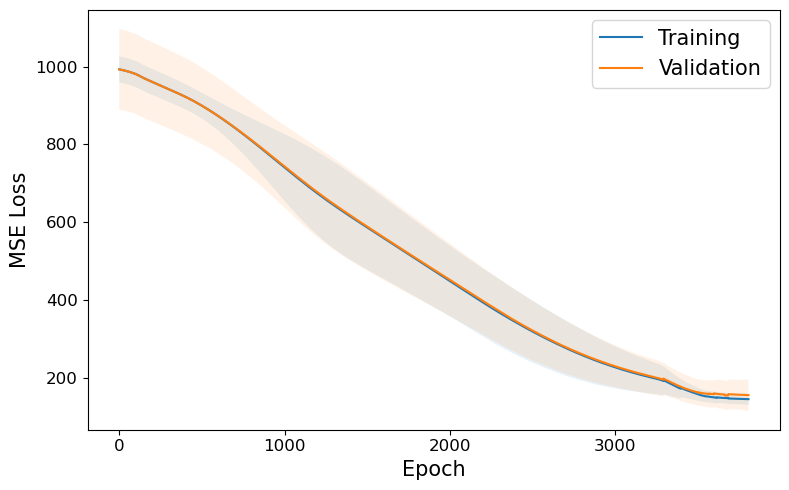

In [23]:
plt.figure(figsize=(8, 5))

# Train
plt.plot(curve_df["epoch"], curve_df["train_loss_mean"], label="Training")
plt.fill_between(
    curve_df["epoch"],
    curve_df["train_loss_mean"] - curve_df["train_loss_std"],
    curve_df["train_loss_mean"] + curve_df["train_loss_std"],
    alpha=0.1
)

# Validation
plt.plot(curve_df["epoch"], curve_df["valid_loss_mean"], label="Validation")
plt.fill_between(
    curve_df["epoch"],
    curve_df["valid_loss_mean"] - curve_df["valid_loss_std"],
    curve_df["valid_loss_mean"] + curve_df["valid_loss_std"],
    alpha=0.1
)

plt.xlabel("Epoch", fontsize=15)
plt.ylabel("MSE Loss", fontsize=15)
plt.xticks(ticks=[0, 1000, 2000, 3000], fontsize=12)
plt.yticks(fontsize=12)
# plt.title(f"Loss Curve", fontsize=16)
plt.legend(fontsize=15)
# plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()